# ST · Ravi / Heiland (human glioblastoma, Visium)

Same pipeline as `st_01_vicari`, applied to 6 patients. Focus: what is **different** from mouse brain.
Read-only unless `SAVE = True` in the last section.

| | Vicari | Ravi/Heiland |
|---|---|---|
| Tissue | healthy mouse brain | human glioblastoma (tumour) |
| Slices | 3, one animal | 6 patients |
| Mito genes | `mt-` | `MT-` |
| Expected low-RNA biology | white matter | white matter **+ necrosis** |
| Expert labels | RegionLoupe (A1/B1) | none in `outs/` (2 extra CSVs to inspect) |

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

from stsm_integration.io import load_config, validate_adata
from stsm_integration.preprocess import st as pst

sc.settings.set_figure_params(dpi=80, frameon=False)

## 0 · Config, paths, Space Ranger summaries

In [2]:
cfg = load_config("../../configs/ravi_heiland.yaml")
RAW = Path(cfg["paths"]["raw_st"])

def outs_dir(st_name: str) -> Path:
    p = RAW / st_name / "outs"
    if not p.exists():
        raise FileNotFoundError(p)
    return p

for s in cfg["slices"]:
    print(s["id"], "→", outs_dir(s["st"]))

UKF248 → /mnt/cbib/stsm_integration/data/RaviHeiland/#UKF248_T_ST/outs
UKF259 → /mnt/cbib/stsm_integration/data/RaviHeiland/#UKF259_T_ST/outs
UKF260 → /mnt/cbib/stsm_integration/data/RaviHeiland/#UKF260_T_ST/outs
UKF262 → /mnt/cbib/stsm_integration/data/RaviHeiland/#UKF262_T_ST/outs
UKF269 → /mnt/cbib/stsm_integration/data/RaviHeiland/#UKF269_T_ST/outs
UKF275 → /mnt/cbib/stsm_integration/data/RaviHeiland/#UKF275_T_ST/outs


Space Ranger writes a run summary per sample. Comparing them **before** any QC shows which patient is technically weaker.

In [3]:
cols = ["Number of Spots Under Tissue", "Mean Reads per Spot", "Median Genes per Spot",
        "Median UMI Counts per Spot", "Fraction Reads in Spots Under Tissue", "Sequencing Saturation"]
summ = pd.concat({s["id"]: pd.read_csv(outs_dir(s["st"]) / "metrics_summary.csv").iloc[0]
                  for s in cfg["slices"]}, axis=1).T
summ[[c for c in cols if c in summ.columns]]

,Number of Spots Under Tissue,Mean Reads per Spot,Median Genes per Spot,Median UMI Counts per Spot,Fraction Reads in Spots Under Tissue,Sequencing Saturation
UKF248,3044,35937.974704,3441.5,9543.0,0.968246,0.551743
UKF259,3604,23477.061876,2337.0,4124.0,0.972976,0.728931
UKF260,2997,30174.0337,2196.0,4038.0,0.946322,0.78851
UKF262,2930,40430.043345,1066.5,2034.5,0.948444,0.918954
UKF269,3217,24121.614548,2360.0,5279.0,0.982351,0.617064
UKF275,3734,23436.5624,2556.0,5521.0,0.985519,0.686025


## 0b · Extra files
`Tab_GeneSet_*.csv` and `Top_GeneExpression_*.csv` exist only for UKF248 and UKF275. Look before deciding whether they matter.

In [4]:
for s in cfg["slices"]:
    for f in sorted((outs_dir(s["st"]) / "spatial").glob("*_T.csv")):
        df = pd.read_csv(f)
        print(f"--- {s['id']} · {f.name} · shape {df.shape}")
        display(df.head(3))

--- UKF248 · Tab_GeneSet_248_T.csv · shape (3044, 7)


,Unnamed: 0,barcodes,Radial Glia,Reactive_Immune,Neuronal Developmemnt,OPC,Reactive-Hypoxia
0,1,AAACAAGTATCTCCCA-1,0.512960,0.339386,0.754444,0.527820,0.601451
1,2,AAACACCAATAACTGC-1,0.810704,0.485472,0.340678,0.574922,0.531951
2,3,AAACAGAGCGACTCCT-1,0.642265,0.303477,0.302546,0.586503,0.471443


--- UKF248 · Top_GeneExpression_248_T.csv · shape (3044, 7)


,Unnamed: 0,barcodes,Radial Glia,Reactive_Immune,Neuronal Developmemnt,OPC,Reactive-Hypoxia
0,1,AAACAAGTATCTCCCA-1,0.512960,0.339386,0.754444,0.527820,0.601451
1,2,AAACACCAATAACTGC-1,0.810704,0.485472,0.340678,0.574922,0.531951
2,3,AAACAGAGCGACTCCT-1,0.642265,0.303477,0.302546,0.586503,0.471443


--- UKF275 · Tab_GeneSet_275_T.csv · shape (3734, 7)


,Unnamed: 0,barcodes,Radial Glia,Reactive_Immune,Neuronal Developmemnt,OPC,Reactive-Hypoxia
0,1,AAACAAGTATCTCCCA-1,0.337026,0.336101,0.219054,0.532180,0.332842
1,2,AAACACCAATAACTGC-1,0.430774,0.462910,0.669760,0.698403,0.424375
2,3,AAACAGAGCGACTCCT-1,0.544694,0.296147,0.131106,0.497354,0.394559


--- UKF275 · Top_GeneExpression_275_T.csv · shape (3734, 7)


,Unnamed: 0,barcodes,Radial Glia,Reactive_Immune,Neuronal Developmemnt,OPC,Reactive-Hypoxia
0,1,AAACAAGTATCTCCCA-1,0.337026,0.336101,0.219054,0.532180,0.332842
1,2,AAACACCAATAACTGC-1,0.430774,0.462910,0.669760,0.698403,0.424375
2,3,AAACAGAGCGACTCCT-1,0.544694,0.296147,0.131106,0.497354,0.394559


## 1 · Load one patient

In [5]:
SLICE = cfg["slices"][0]
adata = pst.load_visium(str(outs_dir(SLICE["st"])), SLICE["id"])
lib = next(iter(adata.uns["spatial"]))
print(adata)
print("scalefactors:", adata.uns["spatial"][lib]["scalefactors"])

/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/

AnnData object with n_obs × n_vars = 3044 × 33538
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'slice_id'
    obsm: 'spatial'
    layers: 'counts'
scalefactors: {'spot_diameter_fullres': 56.14988325881001, 'tissue_hires_scalef': 0.24414062, 'fiducial_diameter_fullres': 90.70365757192387, 'tissue_lowres_scalef': 0.07324219}


## 2 · Coordinates → µm (sanity check: ~100 µm)

In [6]:
pst.coords_to_um(adata)
xy = adata.obsm["spatial"]
d, _ = NearestNeighbors(n_neighbors=2).fit(xy).kneighbors(xy)
print(f"µm/px {adata.uns['um_per_px']:.3f} | extent {np.ptp(xy, axis=0).round(0)} µm | median NN {np.median(d[:, 1]):.1f} µm")

µm/px 1.158 | extent [6000. 6617.] µm | median NN 99.6 µm


## 3 · QC on one patient

**Tumour-specific trap:** necrotic areas have few living cells, so low counts *and* often high mito. They are biology (a hallmark of glioblastoma), not failed spots. The v3 rule (absolute floors, flags for the rest) was designed for this; check it holds.

mito genes: 13


/tmp/ipykernel_3394388/3737046645.py:12: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(tmp, color=["total_counts", "pct_counts_mt"], ncols=2)


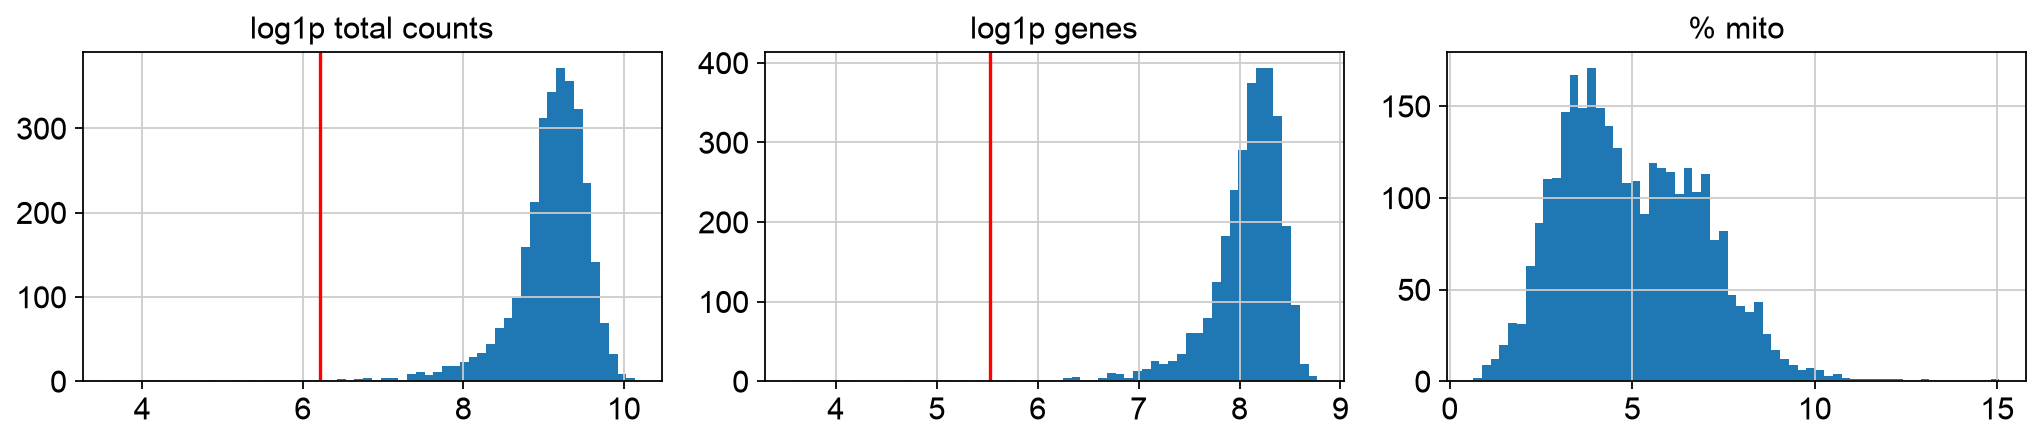

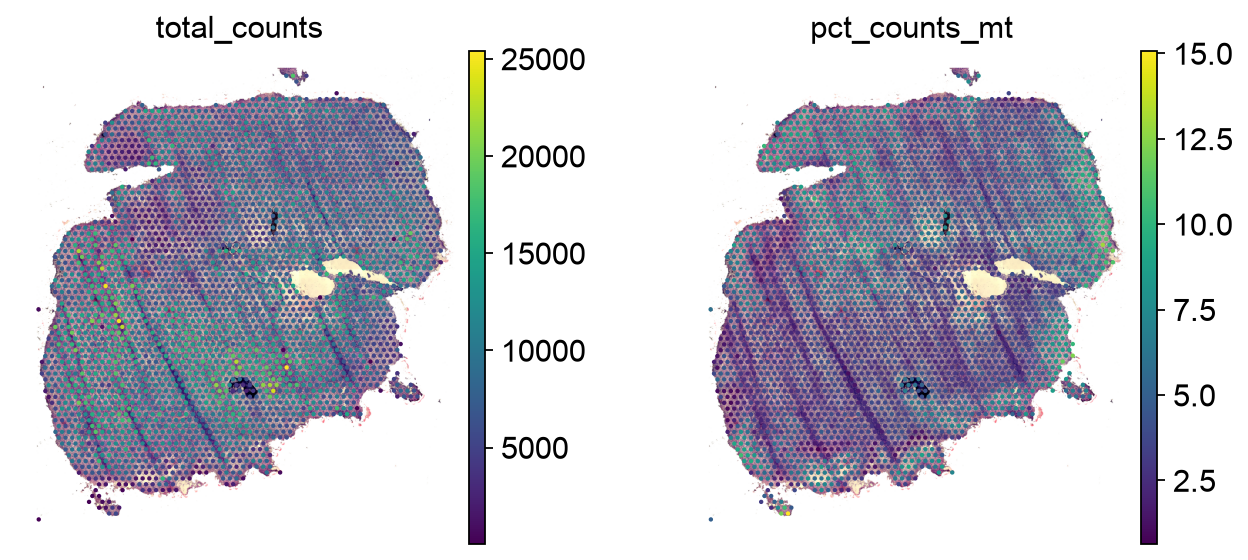

In [7]:
adata.var["mt"] = adata.var_names.str.lower().str.startswith(cfg["st"]["mito_prefix"].lower())
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], layer="counts", percent_top=None, inplace=True)
print("mito genes:", adata.var["mt"].sum())

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].hist(np.log1p(adata.obs["total_counts"]), 60); ax[0].axvline(np.log1p(cfg["st"]["min_counts"]), c="r"); ax[0].set_title("log1p total counts")
ax[1].hist(np.log1p(adata.obs["n_genes_by_counts"]), 60); ax[1].axvline(np.log1p(cfg["st"]["min_genes"]), c="r"); ax[1].set_title("log1p genes")
ax[2].hist(adata.obs["pct_counts_mt"], 60); ax[2].set_title("% mito")
plt.tight_layout()

tmp = adata.copy(); tmp.obsm["spatial"] = tmp.obsm["spatial_px"]
sc.pl.spatial(tmp, color=["total_counts", "pct_counts_mt"], ncols=2)

In [8]:
adata_raw = adata.copy()
adata = pst.qc_filter(adata, mito_prefix=cfg["st"]["mito_prefix"],
                      min_counts=cfg["st"]["min_counts"], min_genes=cfg["st"]["min_genes"],
                      mito_mode=cfg["st"]["mito_mode"])
adata.uns["qc"]

{'spots_in': 3044,
 'spots_out': 3033,
 'genes_in': 33538,
 'genes_out': 21272,
 'min_counts': 500,
 'min_genes': 250,
 'adaptive_counts': 4587.12060546875,
 'adaptive_genes': 1972.4973028177249,
 'n_low_quality_kept': 269,
 'mito_cutoff_pct': 8.93022346496582,
 'mito_mode': 'flag',
 'n_high_mito_kept': 63}

qc_status
clean                 2715
low_quality (kept)     255
high_mito (kept)        63
removed                 11
Name: count, dtype: int64


/tmp/ipykernel_3394388/161725790.py:9: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(tmp, color="qc_status", palette=["lightgrey", "gold", "crimson", "royalblue"])


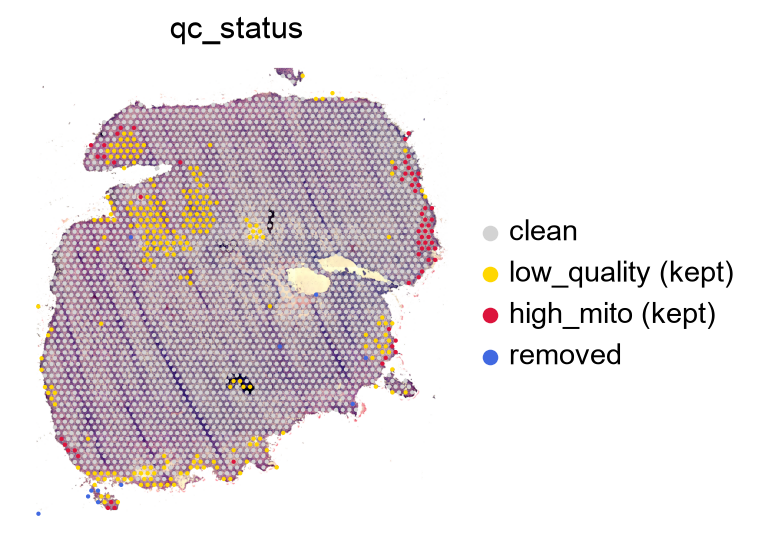

In [9]:
# where are removed / flagged spots?
st_ = pd.Series("clean", index=adata_raw.obs_names, dtype=object)
st_[adata.obs_names[adata.obs["low_quality"]]] = "low_quality (kept)"
st_[adata.obs_names[adata.obs["high_mito"]]] = "high_mito (kept)"
st_[~adata_raw.obs_names.isin(adata.obs_names)] = "removed"
tmp = adata_raw.copy(); tmp.obsm["spatial"] = tmp.obsm["spatial_px"]
tmp.obs["qc_status"] = pd.Categorical(st_, categories=["clean", "low_quality (kept)", "high_mito (kept)", "removed"])
print(tmp.obs["qc_status"].value_counts())
sc.pl.spatial(tmp, color="qc_status", palette=["lightgrey", "gold", "crimson", "royalblue"])

In [10]:
gs = pd.read_csv(outs_dir("#UKF248_T_ST") / "spatial" / "Tab_GeneSet_248_T.csv", index_col="barcodes")
adata.obs["hypoxia"] = adata.obs_names.map(gs["Reactive-Hypoxia"])
print(adata.obs.groupby("low_quality")["hypoxia"].median())
print(adata.obs.groupby("high_mito")["hypoxia"].median())

low_quality
False    0.490008
True     0.551125
Name: hypoxia, dtype: float64
high_mito
False    0.493884
True     0.473149
Name: hypoxia, dtype: float64


**Read the map:** if `low_quality` and `high_mito` overlap in one compact region, it is likely necrosis (check the H&E: pale, acellular). Kept + flagged is the right outcome.

## 4–5 · Normalise and contract

In [11]:
pst.lognormalize(adata)
adata.uns["modality"] = "st"
adata.uns["pixel_size_um"] = cfg["st"]["spot_diameter_um"]
validate_adata(adata, "st")
print("X min/max:", adata.X.min(), adata.X.max(), "| contract OK")

X min/max: 0.0 6.9230886 | contract OK


## 6 · Quick look (not a reference)

/tmp/ipykernel_3394388/1072160316.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(tmp, color=["leiden", "low_quality", "high_mito"], ncols=3)


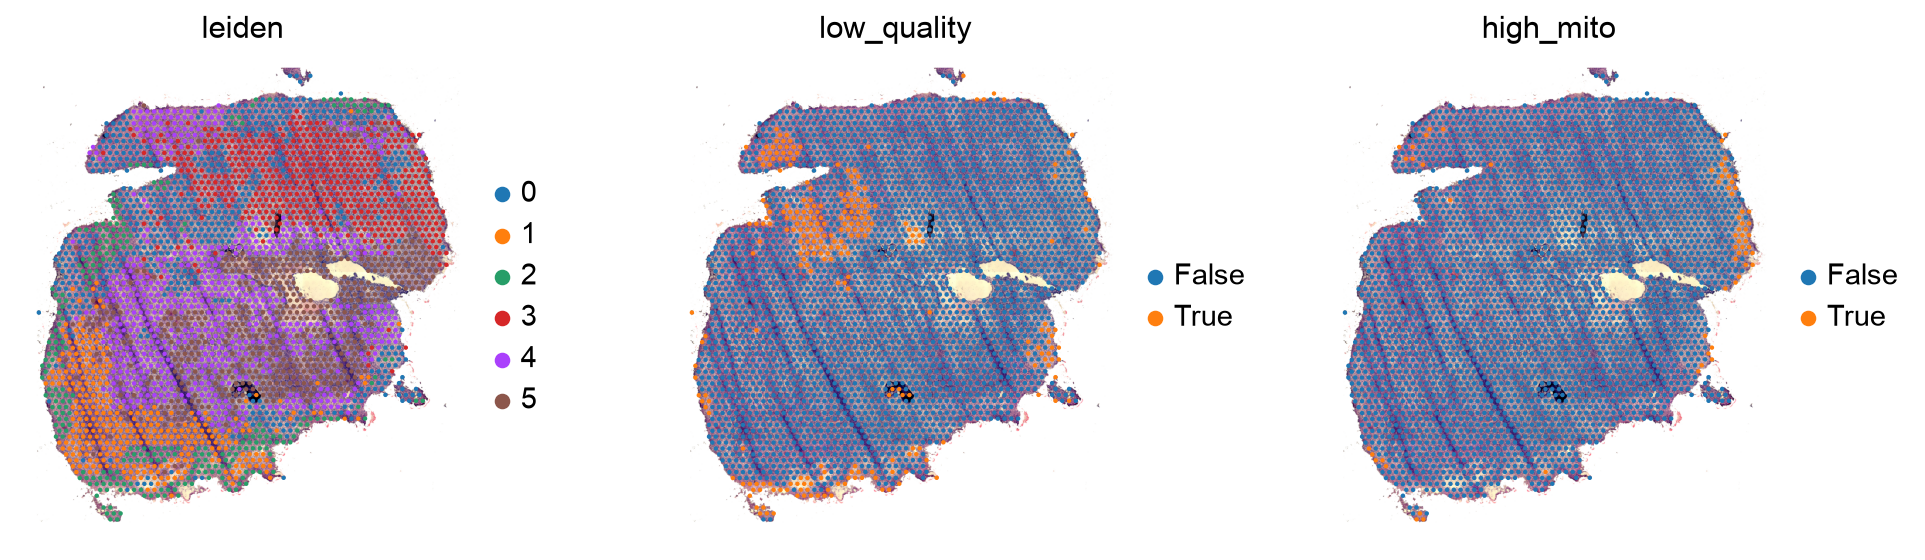

In [12]:
tmp = adata.copy(); tmp.obsm["spatial"] = tmp.obsm["spatial_px"]
sc.pp.highly_variable_genes(tmp, n_top_genes=2000, flavor="seurat_v3", layer="counts")
sc.pp.pca(tmp, mask_var="highly_variable")
sc.pp.neighbors(tmp)
sc.tl.leiden(tmp, resolution=0.5, flavor="igraph", n_iterations=2)
sc.pl.spatial(tmp, color=["leiden", "low_quality", "high_mito"], ncols=3)

## 7 · All patients: QC overview
One row per patient: histograms with floors + QC status map. Removed spots should look technical (edges, tears), never anatomical.

/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integ

,patient,spots,removed,removed_%,low_quality_kept,high_mito_kept,mito_cut_%,genes_out,NN_um
0,UKF248,3044,11,0.4,269,63,8.9,21272,99.6
1,UKF259,3604,24,0.7,188,27,5.0,21616,99.5
2,UKF260,2997,26,0.9,289,337,13.3,21185,99.4
3,UKF262,2930,193,6.6,78,97,31.4,20066,99.1
4,UKF269,3217,32,1.0,35,278,22.0,21563,99.1
5,UKF275,3734,6,0.2,260,63,12.3,21561,99.6


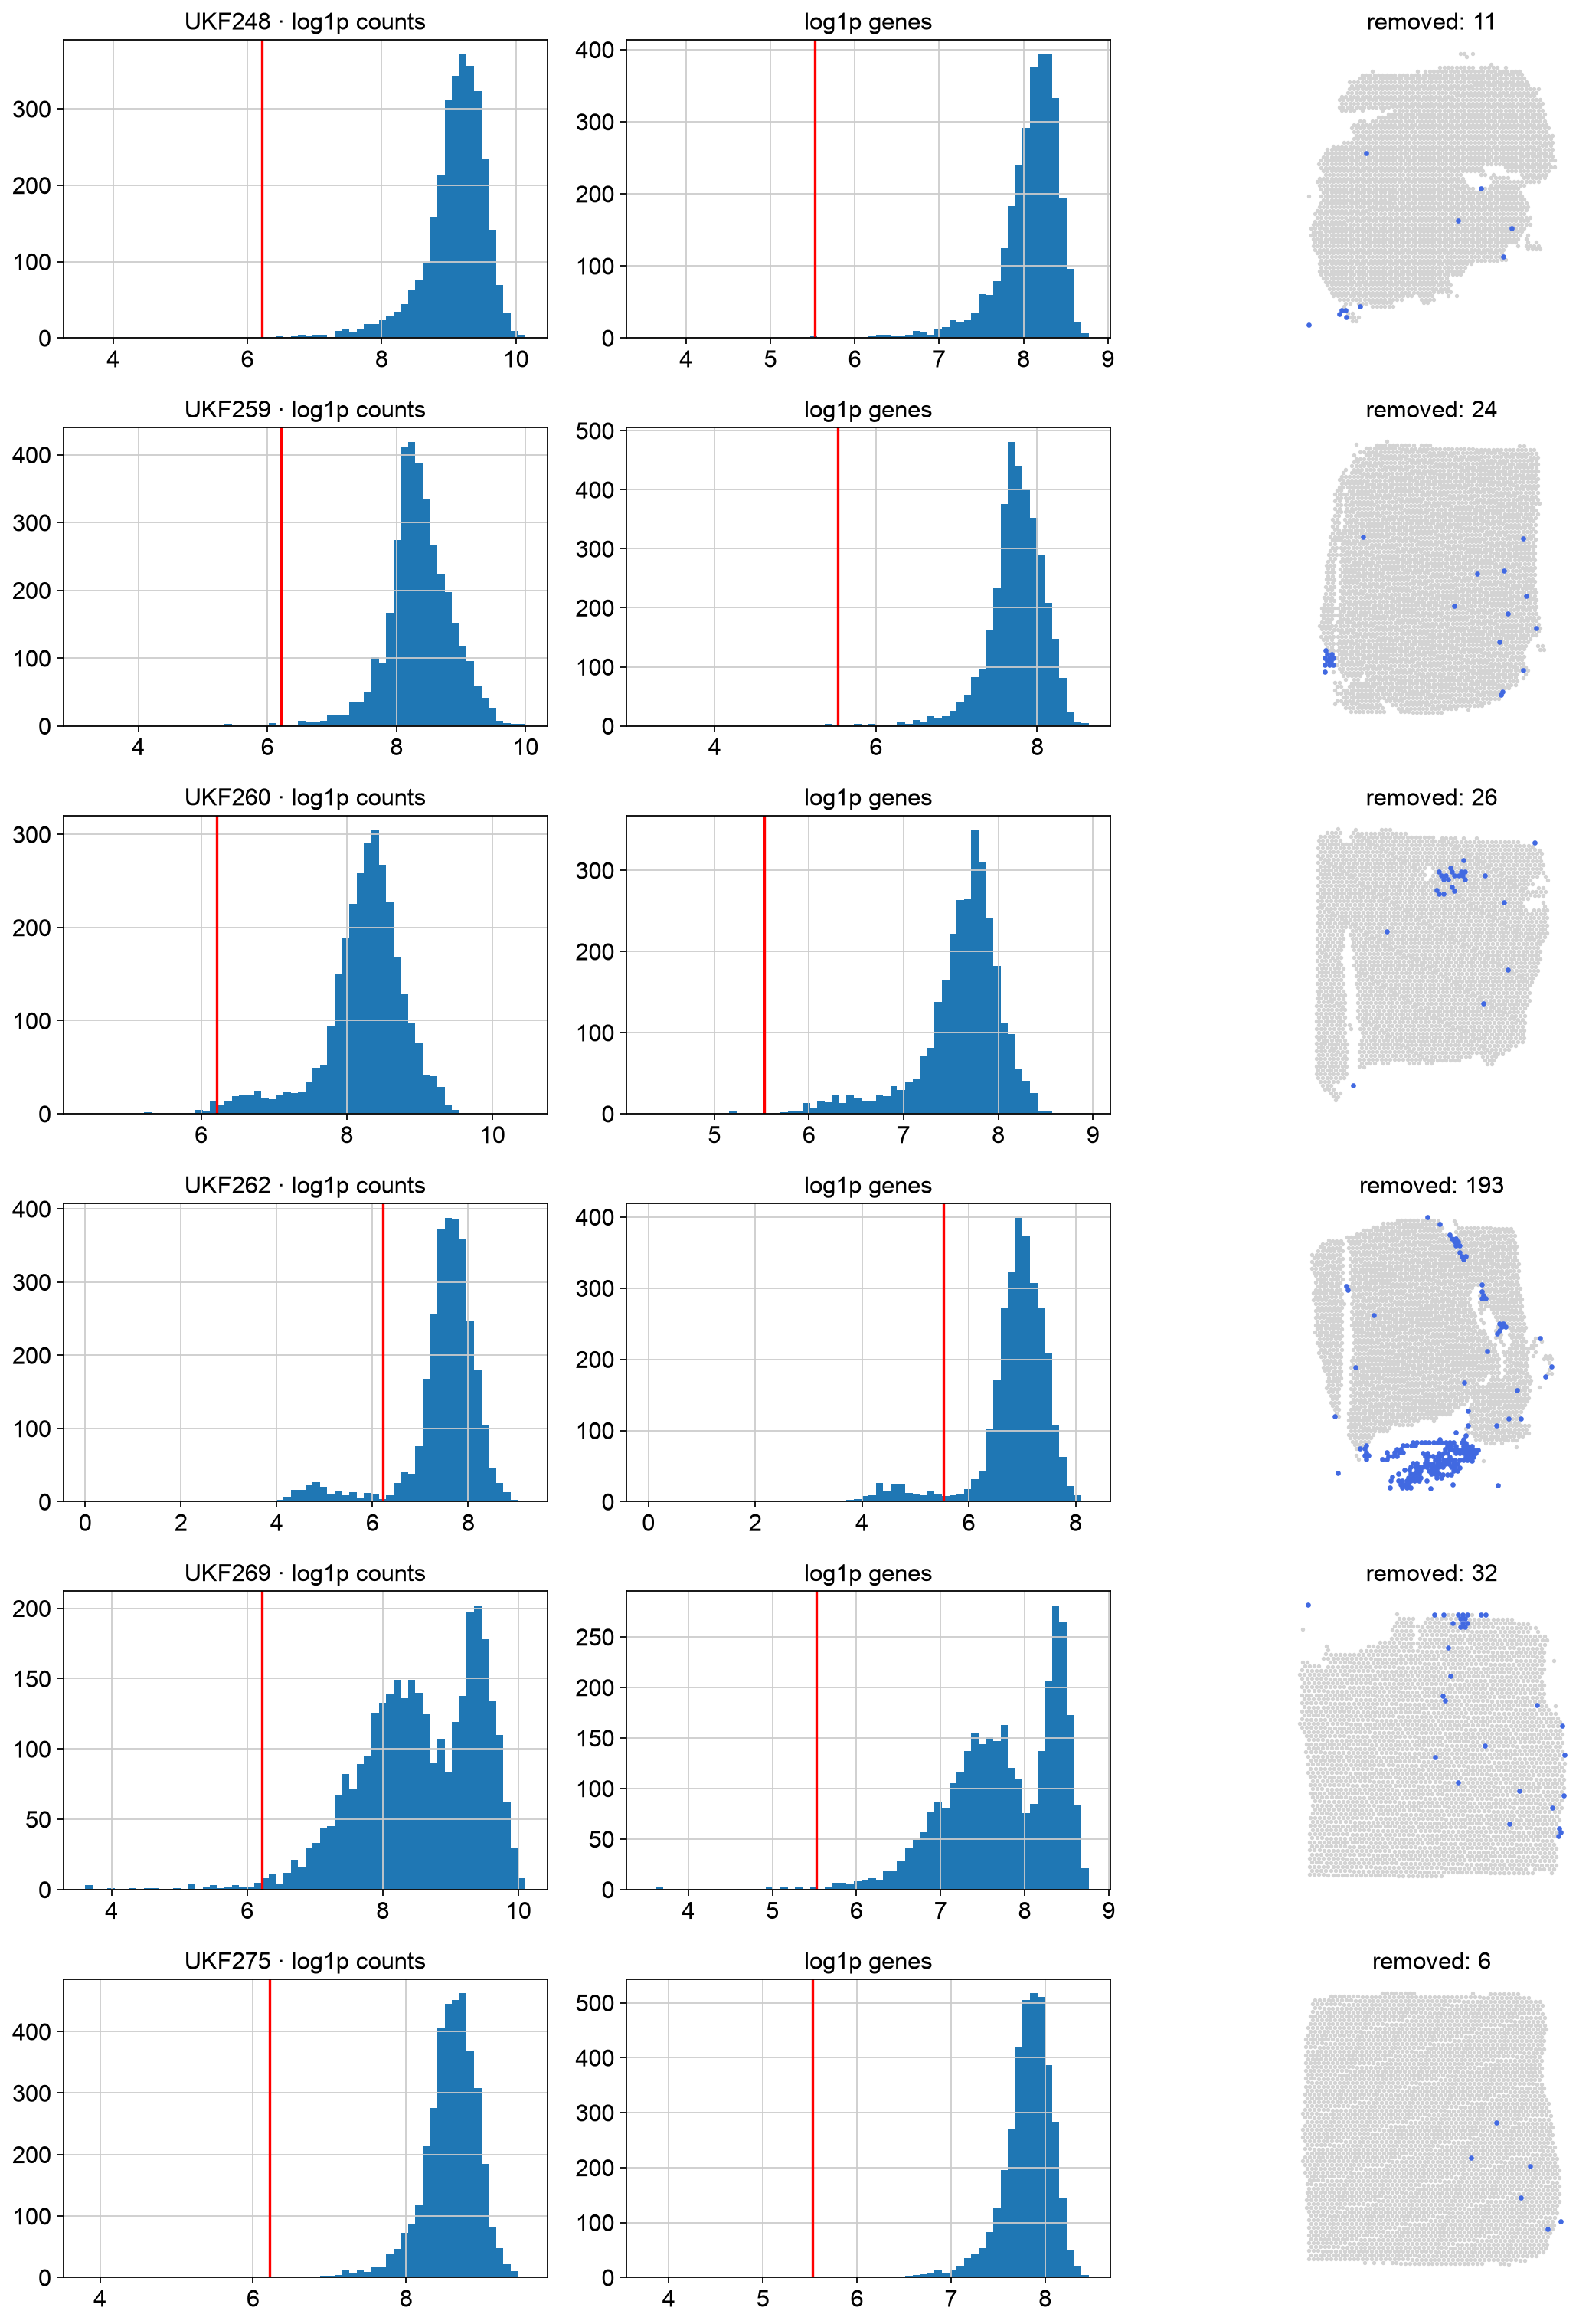

In [13]:
rows, maps = [], []
for s in cfg["slices"]:
    raw = pst.load_visium(str(outs_dir(s["st"])), s["id"])
    pst.coords_to_um(raw)
    raw.var["mt"] = raw.var_names.str.lower().str.startswith(cfg["st"]["mito_prefix"].lower())
    sc.pp.calculate_qc_metrics(raw, qc_vars=["mt"], layer="counts", percent_top=None, inplace=True)
    kept = pst.qc_filter(raw.copy(), mito_prefix=cfg["st"]["mito_prefix"],
                         min_counts=cfg["st"]["min_counts"], min_genes=cfg["st"]["min_genes"],
                         mito_mode=cfg["st"]["mito_mode"])
    d, _ = NearestNeighbors(n_neighbors=2).fit(raw.obsm["spatial"]).kneighbors(raw.obsm["spatial"])
    q = kept.uns["qc"]
    rows.append({"patient": s["id"], "spots": q["spots_in"], "removed": q["spots_in"] - q["spots_out"],
                 "removed_%": round(100 * (1 - q["spots_out"] / q["spots_in"]), 1),
                 "low_quality_kept": q["n_low_quality_kept"], "high_mito_kept": q["n_high_mito_kept"],
                 "mito_cut_%": round(q["mito_cutoff_pct"], 1), "genes_out": q["genes_out"],
                 "NN_um": round(float(np.median(d[:, 1])), 1)})
    raw.obs["removed"] = (~raw.obs_names.isin(kept.obs_names)).astype(str)
    maps.append((s["id"], raw))

display(pd.DataFrame(rows))

fig, axes = plt.subplots(len(maps), 3, figsize=(14, 3.2 * len(maps)))
for (pid, raw), ax in zip(maps, axes):
    ax[0].hist(np.log1p(raw.obs["total_counts"]), 60); ax[0].axvline(np.log1p(cfg["st"]["min_counts"]), c="r"); ax[0].set_title(f"{pid} · log1p counts")
    ax[1].hist(np.log1p(raw.obs["n_genes_by_counts"]), 60); ax[1].axvline(np.log1p(cfg["st"]["min_genes"]), c="r"); ax[1].set_title("log1p genes")
    xy = raw.obsm["spatial"]; rm = raw.obs["removed"] == "True"
    ax[2].scatter(xy[~rm, 0], -xy[~rm, 1], s=2, c="lightgrey"); ax[2].scatter(xy[rm, 0], -xy[rm, 1], s=4, c="royalblue")
    ax[2].set_aspect("equal"); ax[2].set_axis_off(); ax[2].set_title(f"removed: {rm.sum()}")
plt.tight_layout()

## 8 · Save all patients

In [15]:
SAVE = True
out = Path(cfg["paths"]["processed"])
if SAVE:
    out.mkdir(parents=True, exist_ok=True)
    for s in cfg["slices"]:
        a = pst.preprocess_st(pst.load_visium(str(outs_dir(s["st"])), s["id"]), cfg["st"])
        validate_adata(a, "st")
        a.write_h5ad(out / f"{s['id']}.h5ad")
        print("saved", s["id"], a.shape)

/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


saved UKF248 (3033, 21272)


/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


saved UKF259 (3580, 21616)


/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


...

saved UKF262 (2737, 20066)


/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


saved UKF269 (3185, 21563)


/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/cbib/stsm_integration/stsm_integration/.venv/lib64/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


saved UKF275 (3728, 21561)


## Notes / open questions
- Patient IDs: the intern used `Patient_1..6`. SM pairing will use UKF ids; confirm the mapping once SM arrives.
- `H&E/*.jpg` is a separate full-resolution image (not used yet; candidate for histology-based references, P5).
- Extra CSVs (UKF248, UKF275): decide after §0b.
- 